## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
4. Explain the intuition of the elbow, using this numerical simulation as an example.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts?
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Meena Sakthi

**Date:** 10/12/26

In [9]:
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)


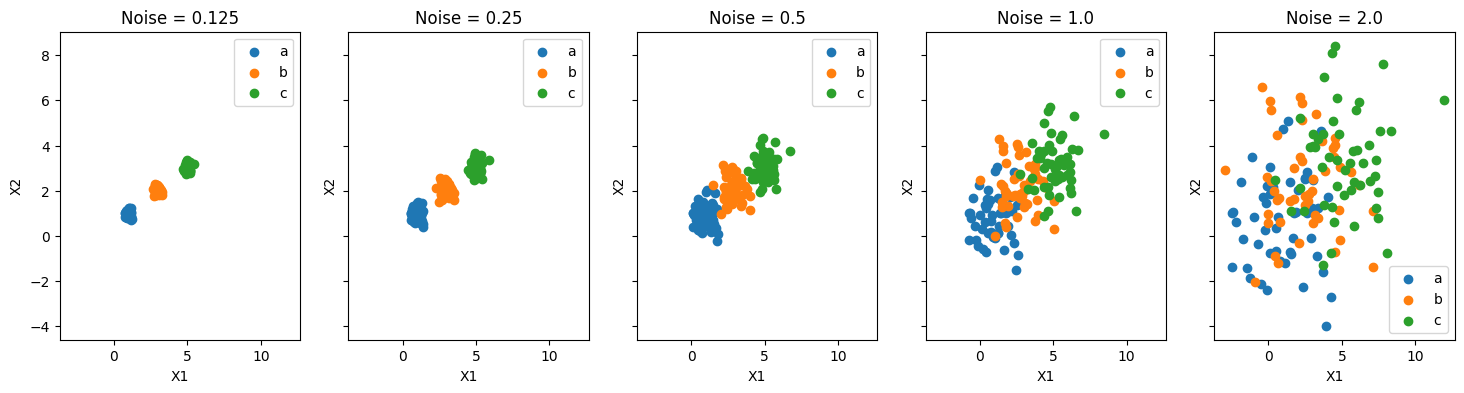

As the noise increases the clusters become more spread out and start overlapping


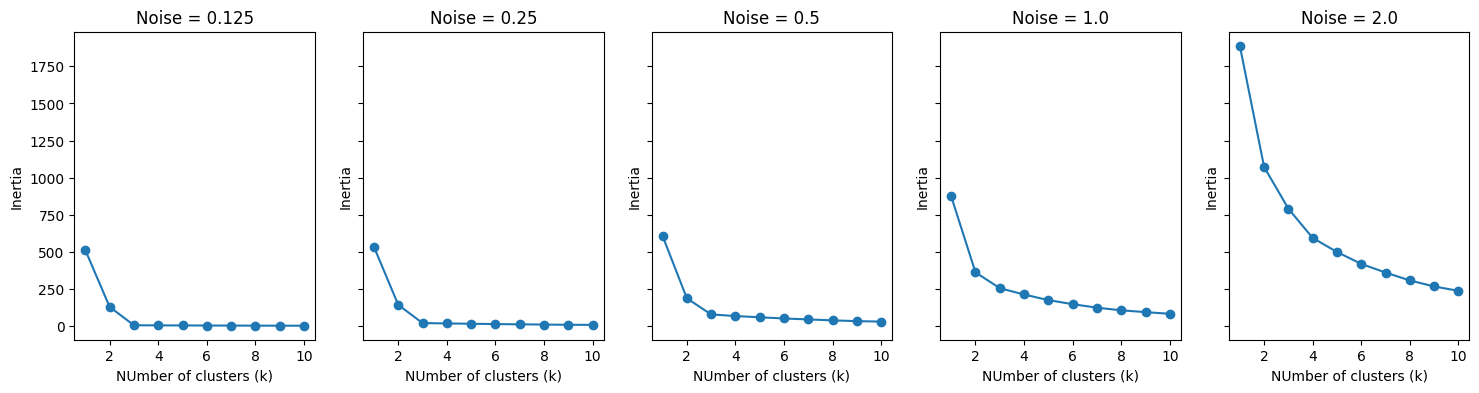

At low noise levels there is a clear elbow at k=3. As the noise increases, the elbow becomes less noticable because the curve decreases more slowly

Q1.4
The elbow method helps find the best number of clusters by looking at where inertia stops decreasing sharply. In this simulation, the elbow is clear at k=3 for lowe noise levels. As noise increases, the elbow becomes less clear because the clusters overlap more.


In [30]:

# Your Phase 1 solution to the problem goes here.
#Q1.2

import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

data = [df0_125, df0_25, df0_5, df1_0, df2_0]
noiselev = [0.125, 0.25, 0.5, 1.0, 2.0]
fig, axes = plt.subplots(1,5,figsize=(18,4), sharex=True, sharey=True)

for i in range(5):
  df = data[i]
  for group in ['a', 'b', 'c']:
    points = df[df['group']== group]
    axes[i].scatter(points['x1'], points['x2'], label=group)

  axes[i].set_title(f'Noise = {noiselev[i]}')
  axes[i].set_xlabel('X1')
  axes[i].set_ylabel('X2')
  axes[i].legend()

plt.show()

print("As the noise increases the clusters become more spread out and start overlapping")

#Q1.3
fig, axes = plt.subplots(1,5,figsize=(18,4), sharey=True)

for i in range(5):
    df = data[i]
    X = df[['x1', 'x2']]
    inertia = []

    for k in range (1,11):
      model = KMeans(n_clusters=k, random_state=42, n_init=10)
      model.fit(X)
      inertia.append(model.inertia_)

    axes[i].plot(range(1,11), inertia, marker ='o')
    axes[i].set_title(f'Noise = {noiselev[i]}')
    axes[i].set_xlabel('NUmber of clusters (k)')
    axes[i].set_ylabel('Inertia')

plt.show()

print("At low noise levels there is a clear elbow at k=3. As the noise increases, the elbow becomes less noticable because the curve decreases more slowly")

#Q.1.4
print("\nQ1.4")
print("The elbow method helps find the best number of clusters by looking at where inertia stops decreasing sharply. In this simulation, the elbow is clear at k=3 for lowe noise levels. As noise increases, the elbow becomes less clear because the clusters overlap more.")



(148, 7)
     index  Year      Country  Spending (2020 USD)  Percent of GDP  \
32      32  2020  Afghanistan           279.576955        0.013589   
66      66  2020      Albania           187.433234        0.012583   
100    100  2020      Algeria          9708.277440        0.066600   
134    134  2020       Angola           993.594405        0.014442   
168    168  2020    Argentina          2830.929705        0.007269   

     Percent of Government Spending  Spending per Capita  
32                         0.049728             7.181899  
66                         0.037952            65.126211  
100                        0.173924           221.392384  
134                        0.074624            30.231680  
168                        0.017268            62.636731  
index                               int64
Year                                int64
Country                            object
Spending (2020 USD)               float64
Percent of GDP                    float64
Percen

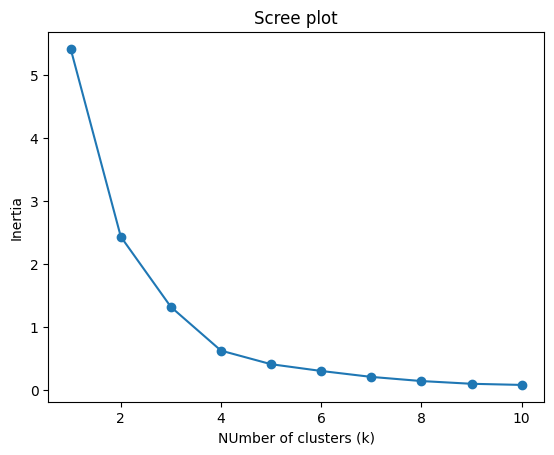

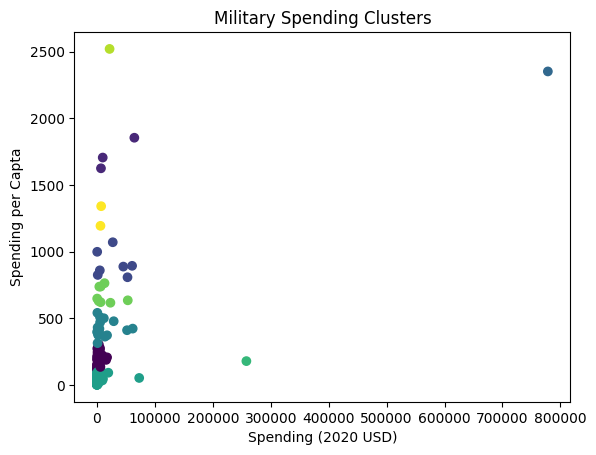

        Spending (2020 USD)                                              \
                      count           mean           std            min   
cluster                                                                   
0                      29.0    3485.954307   4534.024375      18.814132   
1                       3.0   27159.337925  32424.127264    6941.042345   
2                       7.0   27581.249641  25766.181529     436.548223   
3                       1.0  778397.200000           NaN  778397.200000   
4                      16.0   13161.476708  18807.386505     483.415023   
5                      80.0    2240.148777   8523.694476       8.622460   
6                       1.0  257973.429834           NaN  257973.429834   
7                       8.0   13720.862644  17504.313138     405.790494   
8                       1.0   21816.569767           NaN   21816.569767   
9                       2.0    6682.794371    830.264501    6095.708713   

                        

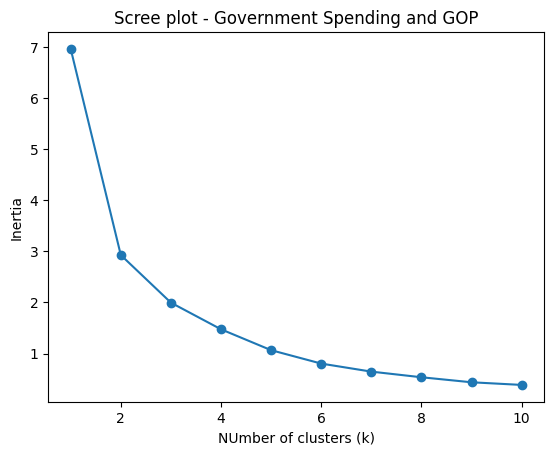

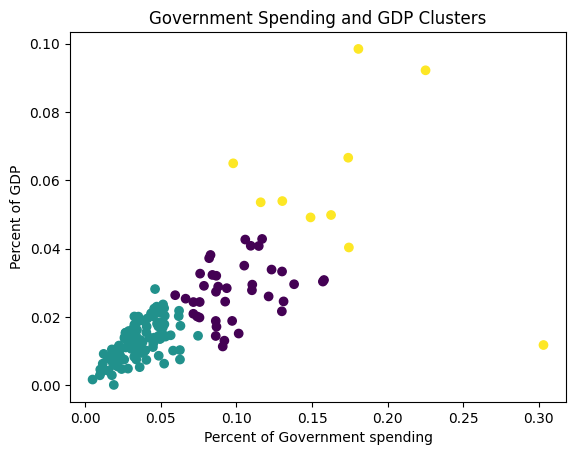

         Percent of Government Spending                                \
                                  count      mean       std       min   
cluster3                                                                
0                                  39.0  0.098683  0.024125  0.059520   
1                                  99.0  0.035777  0.014549  0.004896   
2                                  10.0  0.171289  0.058725  0.097882   

                                                 Percent of GDP            \
               25%       50%       75%       max          count      mean   
cluster3                                                                    
0         0.082430  0.092044  0.112633  0.157918           39.0  0.027412   
1         0.025921  0.034261  0.047402  0.074624           99.0  0.012664   
2         0.135010  0.168248  0.179081  0.303027           10.0  0.058071   

                                                                      
               std       mi

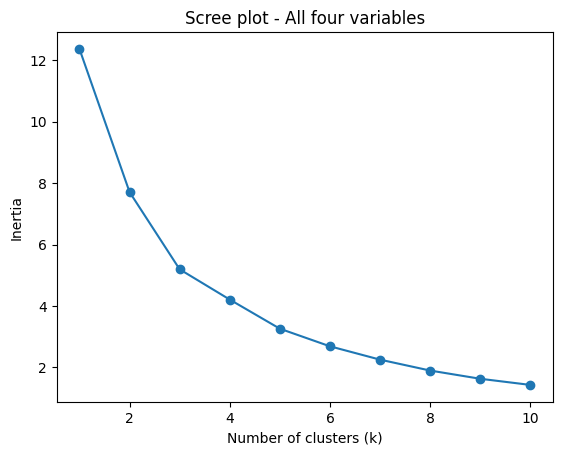

         Spending (2020 USD)                                             \
                       count           mean            std          min   
cluster4                                                                  
0                       86.0    4513.543790   27841.230783     8.622460   
1                        6.0  147964.582042  309635.189564  6095.708713   
2                       26.0   15330.618681   18923.469359   405.790494   
3                       30.0    9073.543709   18135.032885   163.926877   

                                                                  \
                  25%           50%           75%            max   
cluster4                                                           
0           81.022976    288.061512   1138.618231  257973.429834   
1         7700.424616  15897.570598  53872.942442  778397.200000   
2         3176.345598   5857.060906  21818.934764   60675.039625   
3          522.737081   1663.090134   8646.648849   72937.064048  

In [58]:
from sklearn.preprocessing import MinMaxScaler

#Q2.1
df = pd.read_csv("/content/A04-clustering/data/SIPRI Military Expenditure Database.csv")
df = df[df['Year']==2020].copy()
df = df.dropna()
print(df.shape)
print(df.head())
print(df.dtypes)
print("\nAfter filtering for 2020 and removing missing values, 148 countries remain. All four spending variables are numeric, so no further cleaning is required")

#Q2.2
cols = ['Spending (2020 USD)', 'Spending per Capita']
scaler = MinMaxScaler()
X = scaler.fit_transform (df[cols])
inertia = []
for k in range (1,11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X)
    inertia.append(model.inertia_)

plt.plot(range(1,11), inertia, marker ='o')
plt.xlabel('NUmber of clusters (k)')
plt.ylabel('Inertia')
plt.title("Scree plot")
plt.show()

#K-means with 4 clusters
model = KMeans(n_clusters=k, random_state=42, n_init=10)
df['cluster'] = model.fit_predict(X)

plt.scatter(df['Spending (2020 USD)'], df['Spending per Capita'], c=df['cluster'], cmap='viridis')
plt.xlabel('Spending (2020 USD)')
plt.ylabel('Spending per Capta')
plt.title('Military Spending Clusters')
plt.show()

print(df.groupby('cluster')[cols].describe())
print(df[df['Country'].str.contains('United States|USA', case=False, na=False)][['Country', 'cluster']])
print(df.nlargest(5, 'Spending (2020 USD)'), [['Country', 'Spending (2020 USD)', 'cluster']])

#Q2.3
cols3 = ['Percent of Government Spending', 'Percent of GDP']

scalar = MinMaxScaler()
X3 = scalar.fit_transform(df[cols3])
inertia = []

for k in range(1,11):
  model = KMeans(n_clusters=k, random_state=42, n_init=20)
  model.fit(X3)
  inertia.append(model.inertia_)

plt.plot(range(1,11), inertia, marker ='o')
plt.xlabel('NUmber of clusters (k)')
plt.ylabel('Inertia')
plt.title("Scree plot - Government Spending and GOP")
plt.show()

model3 = KMeans(n_clusters=3, random_state=42, n_init=20)
df['cluster3'] = model3.fit_predict(X3)
plt.scatter(df['Percent of Government Spending'], df['Percent of GDP'], c=df['cluster3'], cmap='viridis')
plt.xlabel('Percent of Government spending')
plt.ylabel('Percent of GDP')
plt.title('Government Spending and GDP Clusters')
plt.show()

print(df.groupby('cluster3')[cols3].describe())
print(df[df['Country'].str.contains('United States|USA', case=False, na=False)][['Country', 'cluster3']])
print(pd.crosstab(df['cluster'], df['cluster3']))

print("\n Unlike Q2.2, Q2.3 groups countries based on the percentage of GDP and government spending spen on the miltiary. Most countries fall into the low spending group while 39 are in the middle group and 10 are in the high spending group. The United States belongs to cluster 0 (middle group)")

#Q2.4
cols4 = ['Spending (2020 USD)', 'Spending per Capita', 'Percent of Government Spending', 'Percent of GDP']
scalar = MinMaxScaler()
X4 = scalar.fit_transform(df[cols4])
inertia4 = []

for k in range(1,11):
  model = KMeans(n_clusters=k, random_state=42, n_init=20)
  model.fit(X4)
  inertia4.append(model.inertia_)

plt.plot(range(1,11), inertia4, marker ='o')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Inertia')
plt.title("Scree plot - All four variables")
plt.show()

model4 = KMeans(n_clusters=4, random_state=42, n_init=20)
df['cluster4'] = model4.fit_predict(X4)

print(df.groupby('cluster4')[cols4].describe())
print(df[df['Country'].str.contains('United States|USA', case=False, na=False)][['Country', 'cluster4']])
print(pd.crosstab(df['cluster'], df['cluster4']))
print(pd.crosstab(df['cluster3'], df['cluster4']))

#Q2.4
print("\nUsing all four variables gives a better picture of military spending. Most countries have low spending while a few like the United States have much higher spending. The clusters now consider both total spending and spending relative to GDP and government spending")

#Q2.5
print("Yes K-means showed that most countries spend relatively little on military while some spend much more. High total spending doesn't always mean a high percentage of GDp is spend on the military")


## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]